# Exercise Database Analysis and Visualization

This notebook analyzes the exercise database and visualizes:
- Exercises per muscle group (primary target)
- Exercises per muscle group (including secondary muscles)
- Distribution of exercises by body part, equipment, difficulty, etc.

## 1. Import Libraries and Load Data

In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
import json
import warnings
warnings.filterwarnings('ignore')

# Set style for better-looking plots
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 10

In [21]:
# Load data from Excel file
df = pd.read_excel('data/exercises_db.xlsx', engine='openpyxl')

print(f"Dataset shape: {df.shape}")
print(f"\nColumns: {list(df.columns)}")
print(f"\nFirst few rows:")
df.head()

Dataset shape: (1324, 11)

Columns: ['Serial Number', 'bodyPart', 'equipment', 'id', 'name', 'target', 'secondaryMuscles', 'instructions', 'description', 'difficulty', 'category']

First few rows:


,Serial Number,bodyPart,equipment,id,name,target,secondaryMuscles,instructions,description,difficulty,category
0,1,waist,body weight,1,3/4 sit-up,abs,"hip flexors, lower back",Lie flat on your back with your knees bent and...,The 3/4 sit-up is an abdominal exercise perfor...,beginner,strength
1,2,waist,body weight,2,45° side bend,abs,obliques,Stand with your feet shoulder-width apart and ...,The 45° side bend is a bodyweight exercise tar...,beginner,strength
2,3,waist,body weight,3,air bike,abs,hip flexors,Lie flat on your back with your hands placed b...,The air bike is a bodyweight exercise targetin...,beginner,strength
3,4,waist,body weight,6,alternate heel touchers,abs,obliques,Lie flat on your back with your knees bent and...,Alternate heel touchers is a bodyweight exerci...,beginner,strength
4,5,back,cable,7,alternate lateral pulldown,lats,"biceps, rhomboids",Sit on the cable machine with your back straig...,The alternate lateral pulldown is a cable mach...,beginner,strength


## 2. Basic Dataset Overview

In [22]:
print("=" * 80)
print("DATASET OVERVIEW")
print("=" * 80)
print(f"\nTotal Exercises: {len(df)}")
print(f"\nUnique Body Parts: {df['bodyPart'].nunique()}")
print(f"Unique Target Muscles: {df['target'].nunique()}")
print(f"Unique Equipment Types: {df['equipment'].nunique()}")
print(f"Unique Difficulty Levels: {df['difficulty'].nunique()}")
print(f"\nBody Parts: {sorted(df['bodyPart'].unique())}")
print(f"\nEquipment Types: {sorted(df['equipment'].unique())}")
print(f"\nDifficulty Levels: {sorted(df['difficulty'].unique())}")

DATASET OVERVIEW

Total Exercises: 1324

Unique Body Parts: 10
Unique Target Muscles: 19
Unique Equipment Types: 34
Unique Difficulty Levels: 3

Body Parts: ['back', 'cardio', 'chest', 'lower arms', 'lower legs', 'neck', 'shoulders', 'upper arms', 'upper legs', 'waist']

Equipment Types: ['assisted', 'assisted (towel)', 'band', 'barbell', 'body weight', 'body weight (with resistance band)', 'bosu ball', 'cable', 'dumbbell', 'dumbbell (used as handles for deeper range)', 'dumbbell, exercise ball', 'dumbbell, exercise ball, tennis ball', 'elliptical machine', 'ez barbell', 'ez barbell, exercise ball', 'hammer', 'kettlebell', 'leverage machine', 'medicine ball', 'olympic barbell', 'resistance band', 'roller', 'rope', 'skierg machine', 'sled machine', 'smith machine', 'stability ball', 'stationary bike', 'stepmill machine', 'tire', 'trap bar', 'upper body ergometer', 'weighted', 'wheel roller']

Difficulty Levels: ['advanced', 'beginner', 'intermediate']


## 3. Exercises by Primary Target Muscle

Exercises by Primary Target Muscle:
abs                           :  169 exercises
pectorals                     :  158 exercises
biceps                        :  151 exercises
glutes                        :  144 exercises
delts                         :  143 exercises
triceps                       :  141 exercises
upper back                    :   88 exercises
lats                          :   81 exercises
calves                        :   59 exercises
quads                         :   44 exercises
forearms                      :   37 exercises
cardiovascular system         :   29 exercises
hamstrings                    :   28 exercises
spine                         :   19 exercises
traps                         :   15 exercises
adductors                     :    6 exercises
serratus anterior             :    5 exercises
abductors                     :    5 exercises
levator scapulae              :    2 exercises


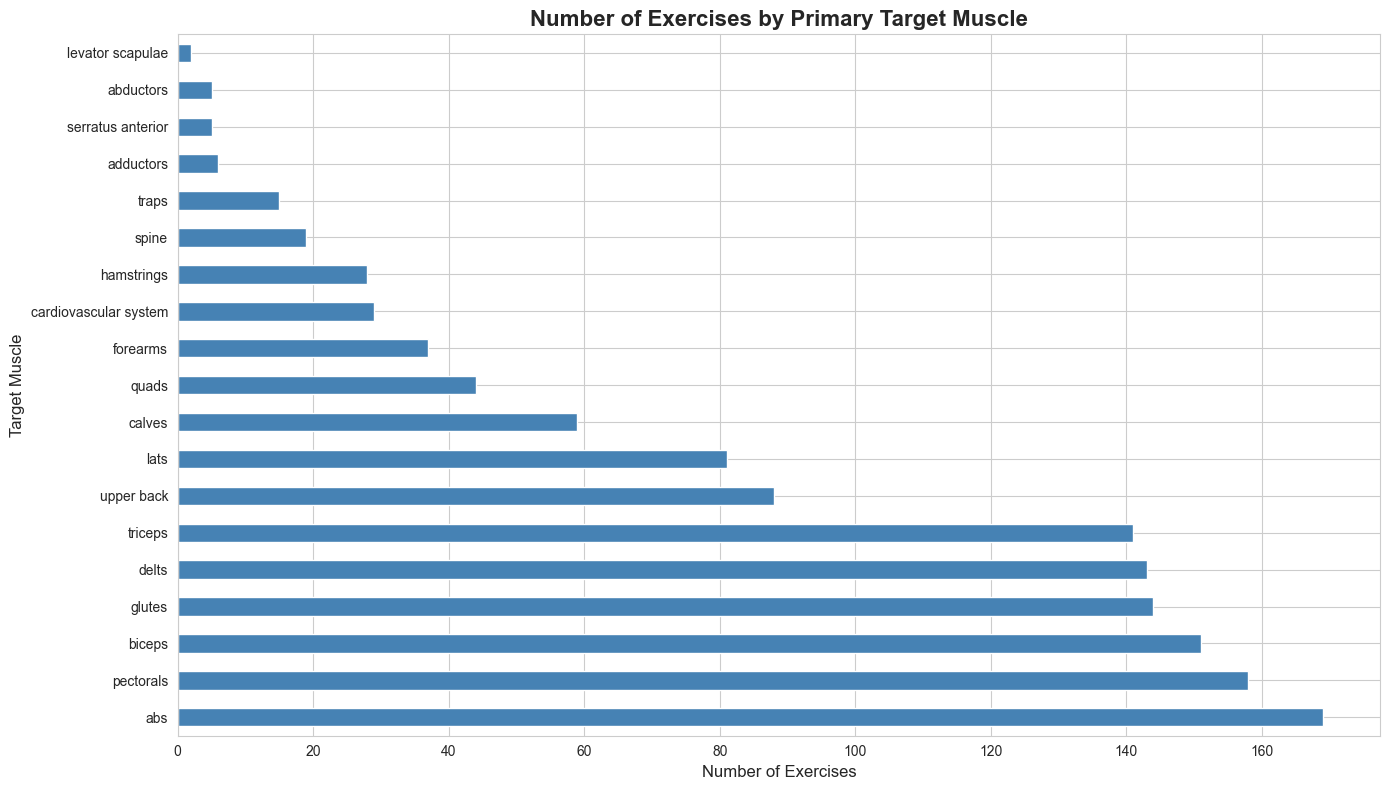

In [23]:
# Count exercises by primary target muscle
target_counts = df['target'].value_counts().sort_values(ascending=False)

print("Exercises by Primary Target Muscle:")
print("=" * 80)
for target, count in target_counts.items():
    print(f"{target:30s}: {count:4d} exercises")

# Visualization
plt.figure(figsize=(14, 8))
target_counts.plot(kind='barh', color='steelblue')
plt.title('Number of Exercises by Primary Target Muscle', fontsize=16, fontweight='bold')
plt.xlabel('Number of Exercises', fontsize=12)
plt.ylabel('Target Muscle', fontsize=12)
plt.tight_layout()
plt.show()

## 4. Exercises by Body Part

Exercises by Body Part:
upper arms                    :  292 exercises
upper legs                    :  227 exercises
back                          :  203 exercises
waist                         :  169 exercises
chest                         :  163 exercises
shoulders                     :  143 exercises
lower legs                    :   59 exercises
lower arms                    :   37 exercises
cardio                        :   29 exercises
neck                          :    2 exercises


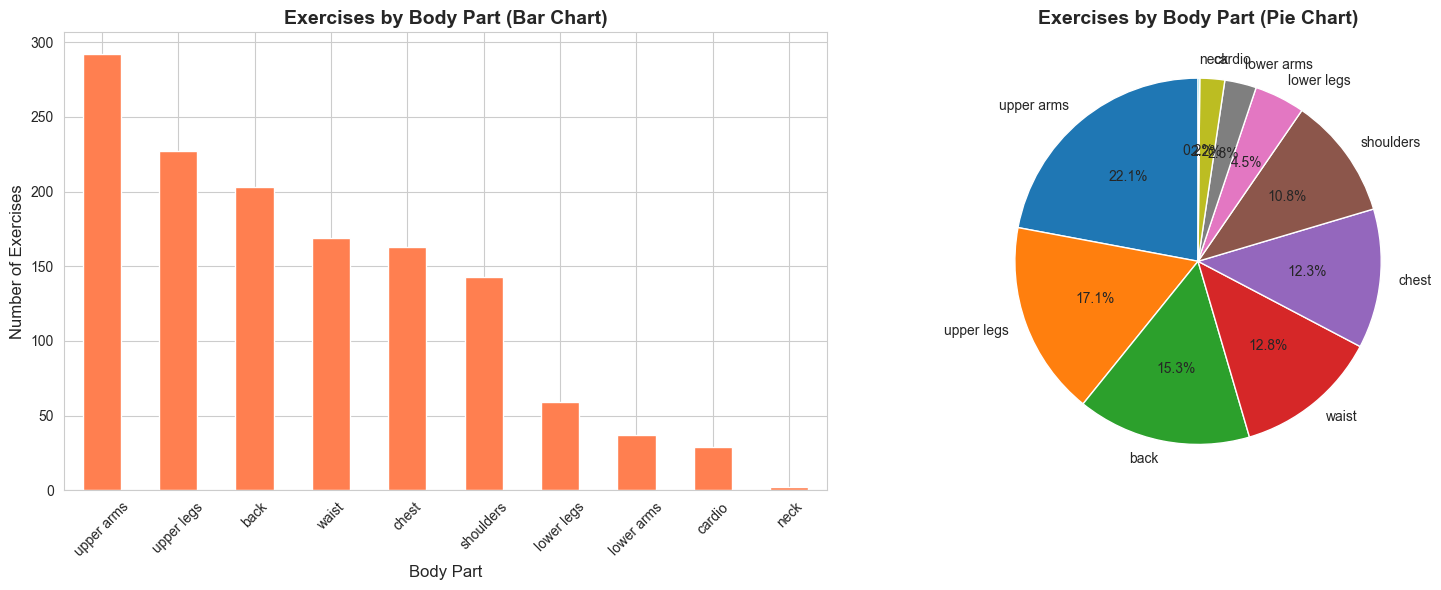

In [24]:
# Count exercises by body part
bodypart_counts = df['bodyPart'].value_counts().sort_values(ascending=False)

print("Exercises by Body Part:")
print("=" * 80)
for bodypart, count in bodypart_counts.items():
    print(f"{bodypart:30s}: {count:4d} exercises")

# Visualization
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Bar chart
bodypart_counts.plot(kind='bar', ax=ax1, color='coral')
ax1.set_title('Exercises by Body Part (Bar Chart)', fontsize=14, fontweight='bold')
ax1.set_xlabel('Body Part', fontsize=12)
ax1.set_ylabel('Number of Exercises', fontsize=12)
ax1.tick_params(axis='x', rotation=45)

# Pie chart
bodypart_counts.plot(kind='pie', ax=ax2, autopct='%1.1f%%', startangle=90)
ax2.set_title('Exercises by Body Part (Pie Chart)', fontsize=14, fontweight='bold')
ax2.set_ylabel('')

plt.tight_layout()
plt.show()

## 5. Exercises per Muscle Group (Including Secondary Muscles)

**This is the key analysis you requested!**

This section counts exercises that target each muscle group, including:
- Primary target muscles
- Secondary muscles

So if an exercise has "abs" as primary target and "hip flexors" and "lower back" as secondary, all three muscle groups get counted.

In [25]:
# Function to parse secondary muscles (they might be stored as strings)
def parse_secondary_muscles(secondary_muscles_str):
    """Parse secondary muscles from string format."""
    if pd.isna(secondary_muscles_str) or secondary_muscles_str == '':
        return []
    
    # If it's already a list, return it
    if isinstance(secondary_muscles_str, list):
        return [m.strip() for m in secondary_muscles_str if m]
    
    # If it's a string, split by comma
    if isinstance(secondary_muscles_str, str):
        return [m.strip() for m in secondary_muscles_str.split(',') if m.strip()]
    
    return []

# Count all muscles (primary + secondary)
muscle_counter = Counter()

for idx, row in df.iterrows():
    # Add primary target
    primary_target = row.get('target', '')
    if pd.notna(primary_target) and primary_target != '':
        muscle_counter[primary_target] += 1
    
    # Add secondary muscles
    secondary_muscles = parse_secondary_muscles(row.get('secondaryMuscles', ''))
    for muscle in secondary_muscles:
        if muscle:  # Only count non-empty muscles
            muscle_counter[muscle] += 1

# Convert to DataFrame for easier handling
muscle_df = pd.DataFrame({
    'Muscle Group': list(muscle_counter.keys()),
    'Exercise Count': list(muscle_counter.values())
}).sort_values('Exercise Count', ascending=False)

print("=" * 80)
print("EXERCISES PER MUSCLE GROUP (Including Primary Target + Secondary Muscles)")
print("=" * 80)
print(f"\nTotal unique muscle groups: {len(muscle_df)}")
print(f"\nTop 20 Muscle Groups:")
print("-" * 80)
for idx, row in muscle_df.head(20).iterrows():
    print(f"{row['Muscle Group']:30s}: {int(row['Exercise Count']):4d} exercises")

# Display full table
print(f"\n\nFull Table ({len(muscle_df)} muscle groups):")
display(muscle_df)

EXERCISES PER MUSCLE GROUP (Including Primary Target + Secondary Muscles)

Total unique muscle groups: 50

Top 20 Muscle Groups:
--------------------------------------------------------------------------------
triceps                       :  409 exercises
shoulders                     :  400 exercises
biceps                        :  345 exercises
hamstrings                    :  317 exercises
forearms                      :  314 exercises
glutes                        :  280 exercises
calves                        :  206 exercises
abs                           :  169 exercises
quadriceps                    :  161 exercises
pectorals                     :  158 exercises
delts                         :  143 exercises
upper back                    :  125 exercises
core                          :   94 exercises
chest                         :   91 exercises
lats                          :   82 exercises
hip flexors                   :   77 exercises
obliques                      :   72 e

,Muscle Group,Exercise Count
8,triceps,409
9,shoulders,400
5,biceps,345
12,hamstrings,317
11,forearms,314
13,glutes,280
16,calves,206
0,abs,169
10,quadriceps,161
7,pectorals,158


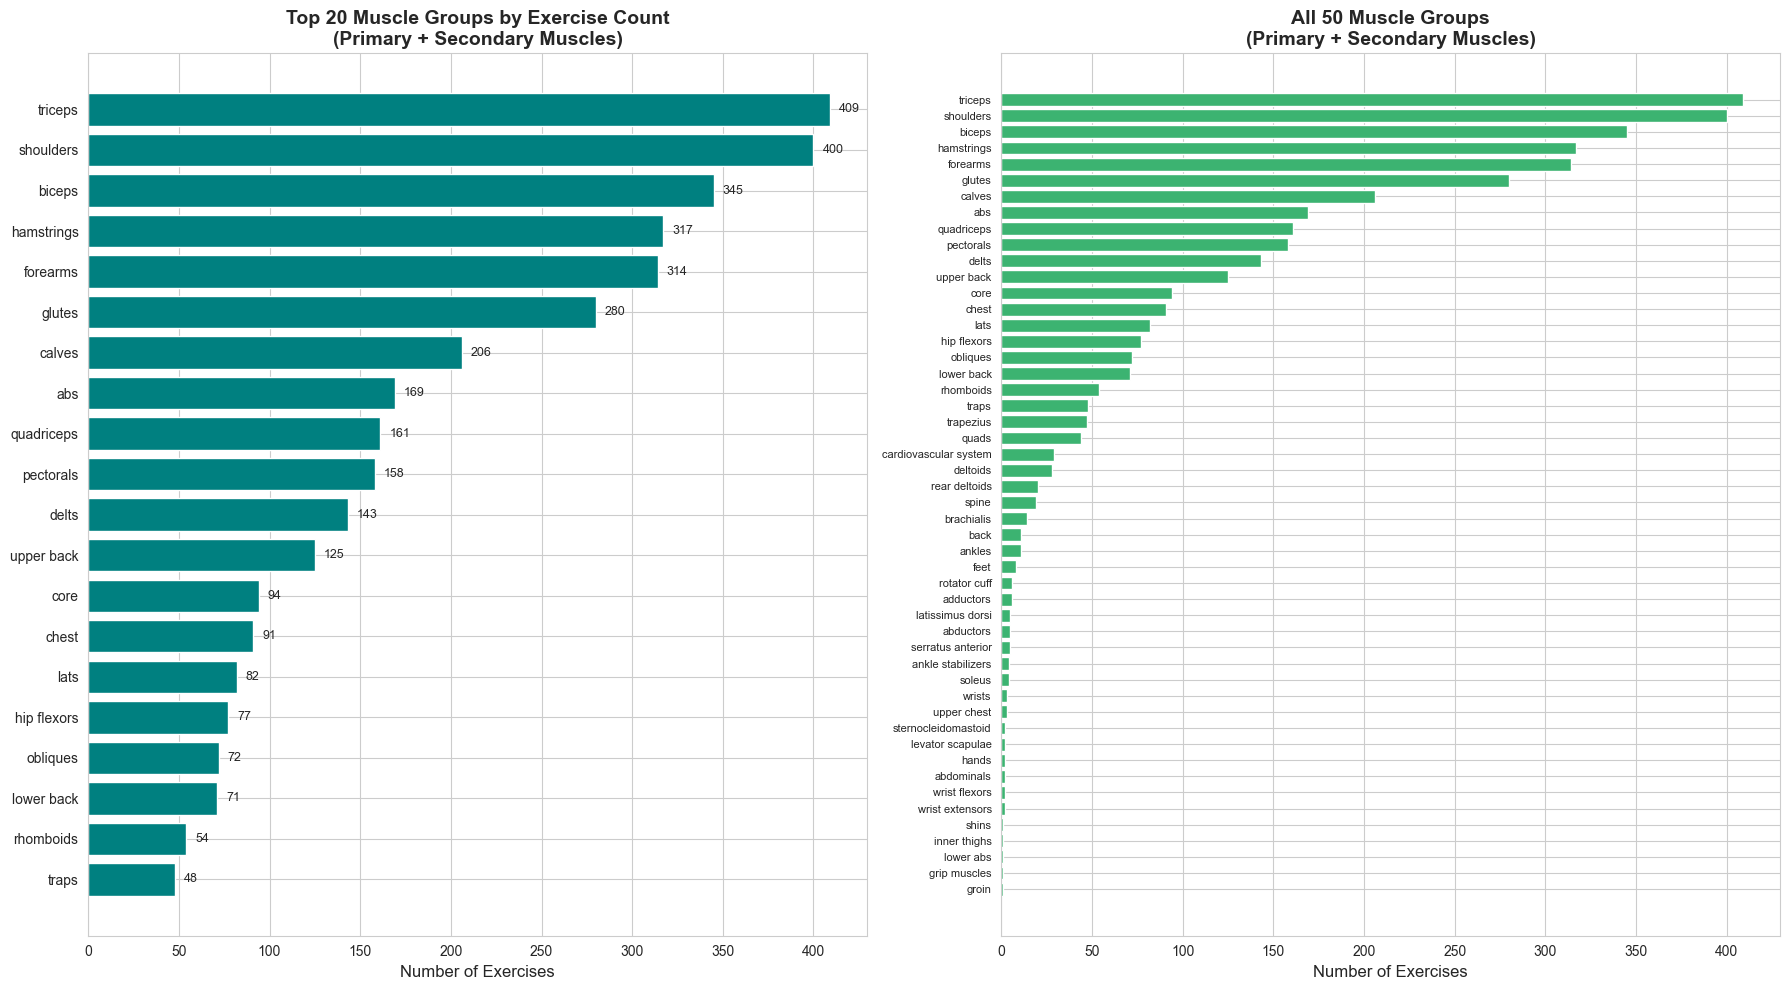

In [26]:
# Visualization: Exercises per Muscle Group (All muscles)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 10))

# Top 20 muscle groups - Bar chart
top_20 = muscle_df.head(20)
ax1.barh(range(len(top_20)), top_20['Exercise Count'], color='teal')
ax1.set_yticks(range(len(top_20)))
ax1.set_yticklabels(top_20['Muscle Group'])
ax1.set_xlabel('Number of Exercises', fontsize=12)
ax1.set_title('Top 20 Muscle Groups by Exercise Count\n(Primary + Secondary Muscles)', 
              fontsize=14, fontweight='bold')
ax1.invert_yaxis()

# Add value labels on bars
for i, v in enumerate(top_20['Exercise Count']):
    ax1.text(v + 5, i, str(int(v)), va='center', fontsize=9)

# All muscle groups - Bar chart (smaller font)
ax2.barh(range(len(muscle_df)), muscle_df['Exercise Count'], color='mediumseagreen')
ax2.set_yticks(range(len(muscle_df)))
ax2.set_yticklabels(muscle_df['Muscle Group'], fontsize=8)
ax2.set_xlabel('Number of Exercises', fontsize=12)
ax2.set_title(f'All {len(muscle_df)} Muscle Groups\n(Primary + Secondary Muscles)', 
              fontsize=14, fontweight='bold')
ax2.invert_yaxis()

plt.tight_layout()
plt.show()

## 6. Comparison: Primary Target vs All Muscles (Primary + Secondary)

Comparison: Primary Target vs Primary + Secondary Muscles


,Primary Target Only,Primary + Secondary,Total
triceps,141.0,409,409
shoulders,0.0,400,400
biceps,151.0,345,345
hamstrings,28.0,317,317
forearms,37.0,314,314
glutes,144.0,280,280
calves,59.0,206,206
abs,169.0,169,169
quadriceps,0.0,161,161
pectorals,158.0,158,158


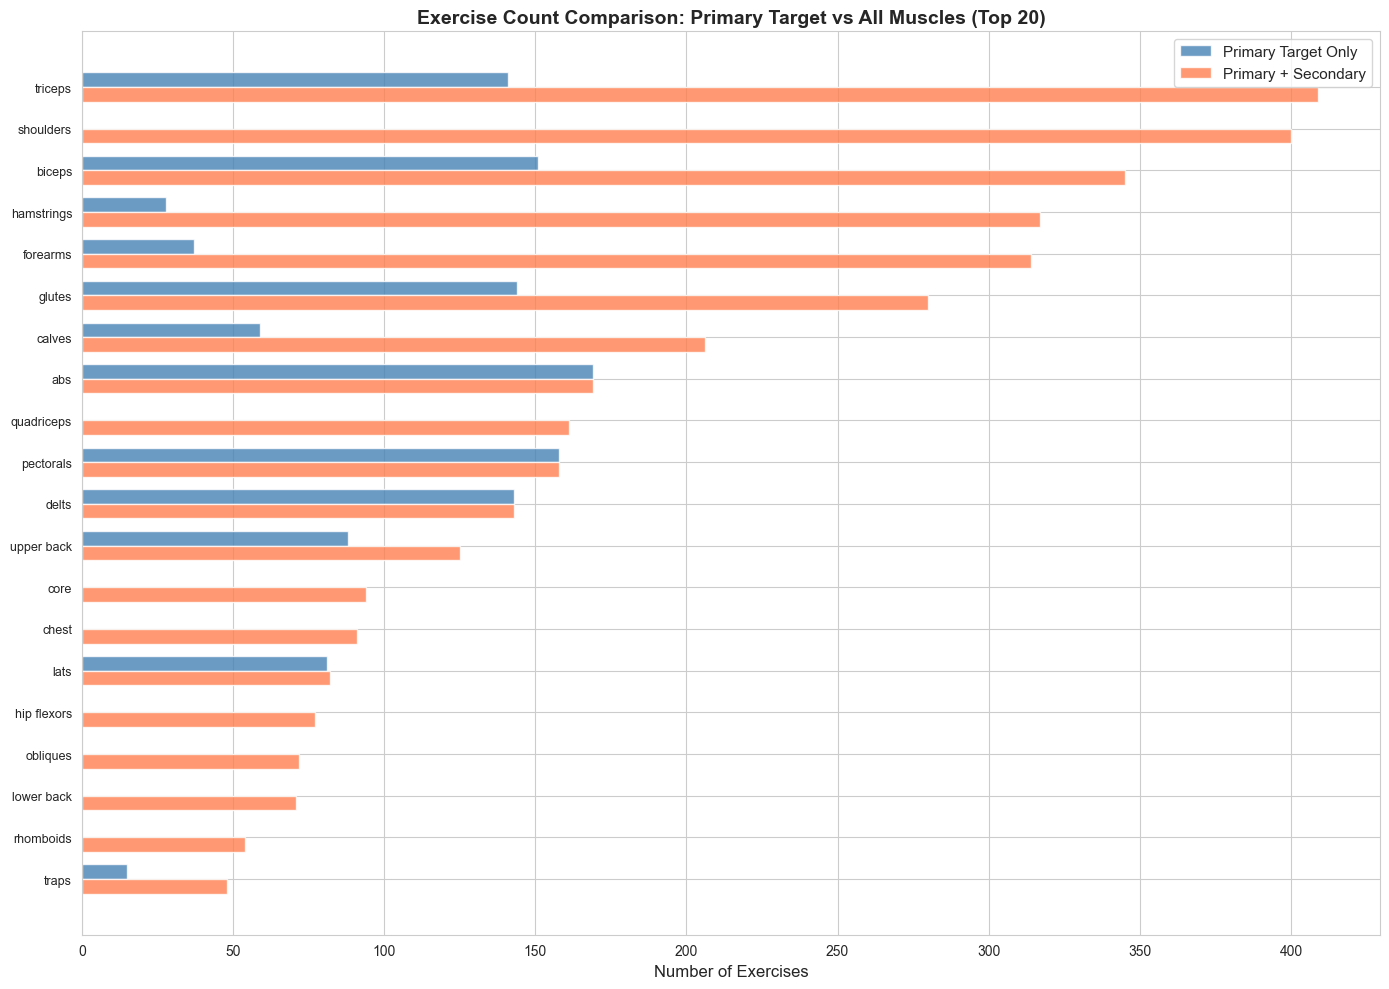

In [27]:
# Get primary target counts (sorted by count, descending)
primary_target_counts = df['target'].value_counts().sort_values(ascending=False)

# Get all muscle counts (from muscle_df) - sorted by count for comparison
all_muscle_counts = muscle_df.set_index('Muscle Group')['Exercise Count'].sort_values(ascending=False)

# Create comparison DataFrame
comparison_df = pd.DataFrame({
    'Primary Target Only': primary_target_counts,
    'Primary + Secondary': all_muscle_counts
}).fillna(0)

# Sort by total count
comparison_df['Total'] = comparison_df['Primary + Secondary']
comparison_df = comparison_df.sort_values('Total', ascending=False)

print("Comparison: Primary Target vs Primary + Secondary Muscles")
print("=" * 80)
display(comparison_df.head(20))

# Visualization
fig, ax = plt.subplots(figsize=(14, 10))

x = np.arange(len(comparison_df.head(20)))
width = 0.35

ax.barh(x - width/2, comparison_df.head(20)['Primary Target Only'], 
        width, label='Primary Target Only', color='steelblue', alpha=0.8)
ax.barh(x + width/2, comparison_df.head(20)['Primary + Secondary'], 
        width, label='Primary + Secondary', color='coral', alpha=0.8)

ax.set_yticks(x)
ax.set_yticklabels(comparison_df.head(20).index, fontsize=9)
ax.set_xlabel('Number of Exercises', fontsize=12)
ax.set_title('Exercise Count Comparison: Primary Target vs All Muscles (Top 20)', 
             fontsize=14, fontweight='bold')
ax.legend(fontsize=11)
ax.invert_yaxis()

plt.tight_layout()
plt.show()

## 7. Exercises by Equipment Type

Exercises by Equipment Type:
body weight                   :  324 exercises
dumbbell                      :  285 exercises
cable                         :  157 exercises
barbell                       :  154 exercises
leverage machine              :   81 exercises
band                          :   54 exercises
smith machine                 :   48 exercises
kettlebell                    :   41 exercises
weighted                      :   36 exercises
stability ball                :   28 exercises
ez barbell                    :   22 exercises
sled machine                  :   15 exercises
assisted                      :   14 exercises
medicine ball                 :   13 exercises
rope                          :   10 exercises
roller                        :    8 exercises
resistance band               :    7 exercises
dumbbell, exercise ball       :    7 exercises
bosu ball                     :    3 exercises
olympic barbell               :    2 exercises
wheel roller                  :

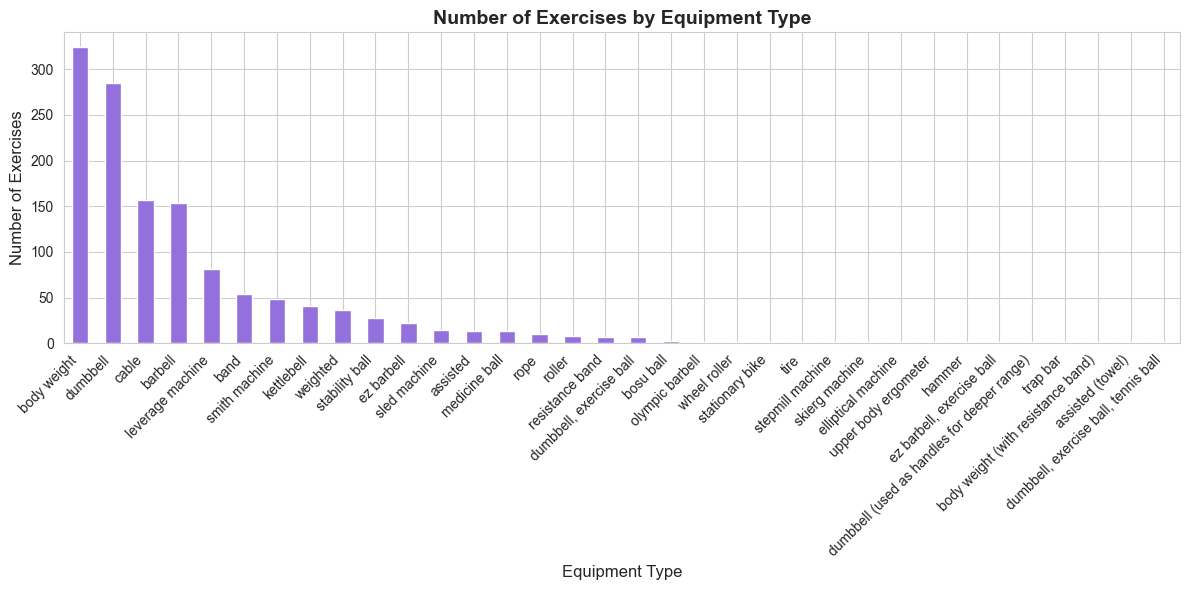

In [28]:
# Count exercises by equipment
equipment_counts = df['equipment'].value_counts().sort_values(ascending=False)

print("Exercises by Equipment Type:")
print("=" * 80)
for equipment, count in equipment_counts.items():
    print(f"{equipment:30s}: {count:4d} exercises")

# Visualization
plt.figure(figsize=(12, 6))
equipment_counts.plot(kind='bar', color='mediumpurple')
plt.title('Number of Exercises by Equipment Type', fontsize=14, fontweight='bold')
plt.xlabel('Equipment Type', fontsize=12)
plt.ylabel('Number of Exercises', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

## 8. Exercises by Difficulty Level

Exercises by Difficulty Level:
intermediate        :  589 exercises
beginner            :  567 exercises
advanced            :  168 exercises


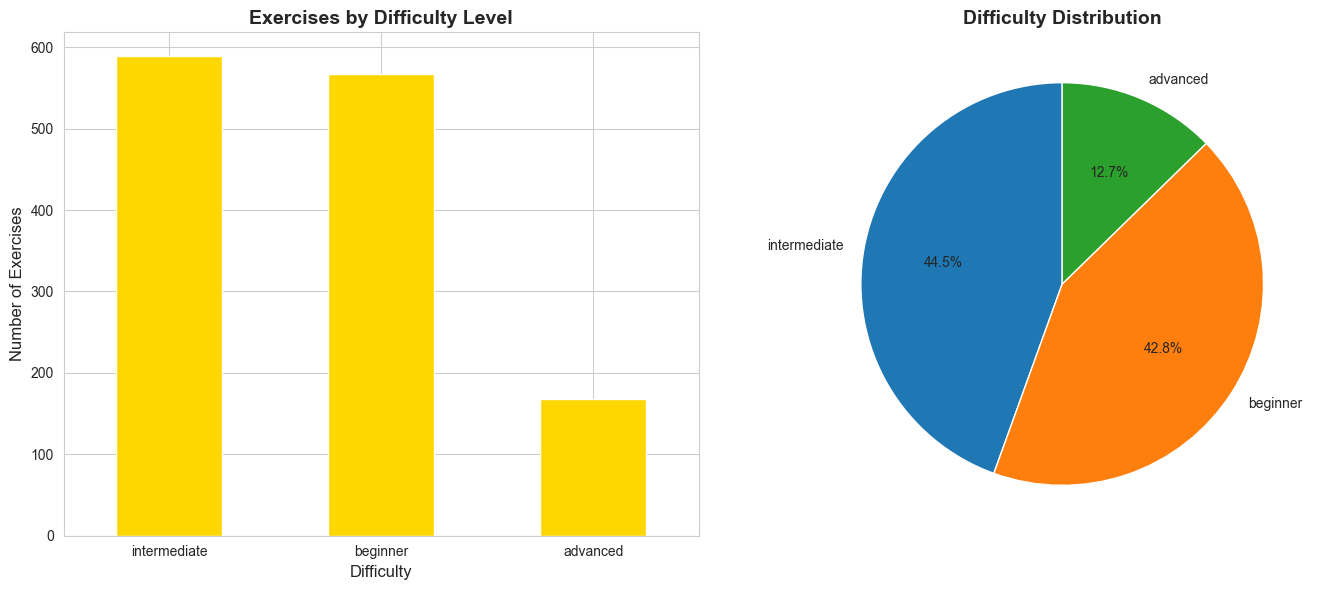

In [29]:
# Count exercises by difficulty
difficulty_counts = df['difficulty'].value_counts()

print("Exercises by Difficulty Level:")
print("=" * 80)
for difficulty, count in difficulty_counts.items():
    print(f"{difficulty:20s}: {count:4d} exercises")

# Visualization
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Bar chart
difficulty_counts.plot(kind='bar', ax=ax1, color='gold')
ax1.set_title('Exercises by Difficulty Level', fontsize=14, fontweight='bold')
ax1.set_xlabel('Difficulty', fontsize=12)
ax1.set_ylabel('Number of Exercises', fontsize=12)
ax1.tick_params(axis='x', rotation=0)

# Pie chart
difficulty_counts.plot(kind='pie', ax=ax2, autopct='%1.1f%%', startangle=90)
ax2.set_title('Difficulty Distribution', fontsize=14, fontweight='bold')
ax2.set_ylabel('')

plt.tight_layout()
plt.show()

## 9. Exercises by Category

Exercises by Category:
strength                      : 1180 exercises
stretching                    :   53 exercises
cardio                        :   34 exercises
mobility                      :   31 exercises
plyometrics                   :   17 exercises
balance                       :    5 exercises
rehabilitation                :    4 exercises


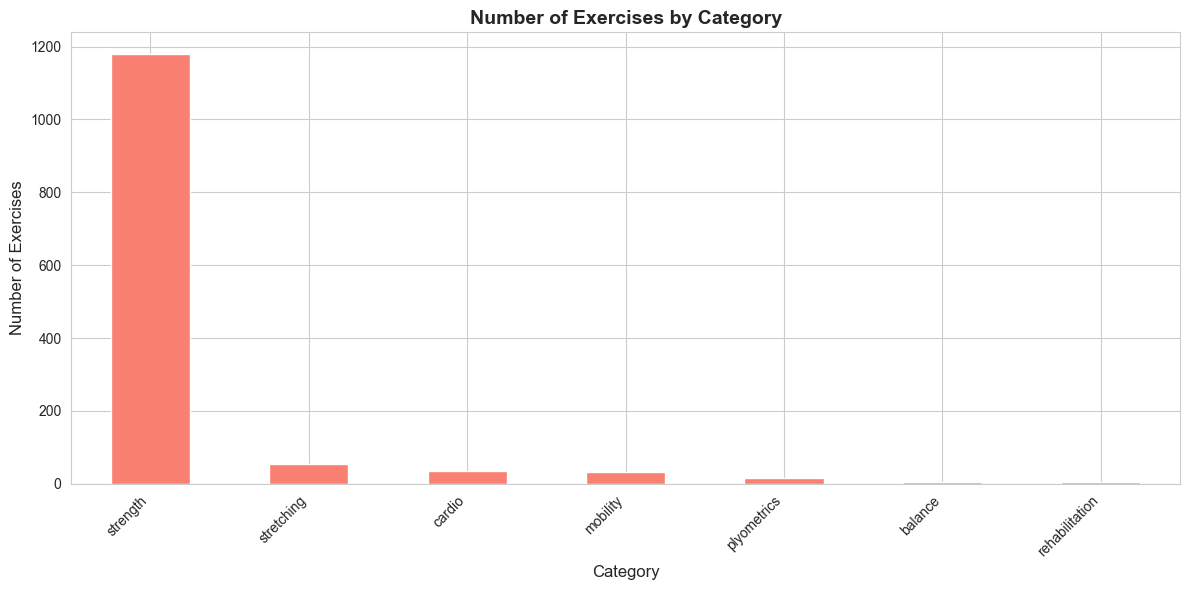

In [30]:
# Count exercises by category
if 'category' in df.columns:
    category_counts = df['category'].value_counts().sort_values(ascending=False)
    
    print("Exercises by Category:")
    print("=" * 80)
    for category, count in category_counts.items():
        print(f"{category:30s}: {count:4d} exercises")
    
    # Visualization
    plt.figure(figsize=(12, 6))
    category_counts.plot(kind='bar', color='salmon')
    plt.title('Number of Exercises by Category', fontsize=14, fontweight='bold')
    plt.xlabel('Category', fontsize=12)
    plt.ylabel('Number of Exercises', fontsize=12)
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()
else:
    print("Category column not found in dataset")

## 10. Muscle Group Coverage Analysis

This shows which exercises target multiple muscle groups and how many secondary muscles each exercise has.

Secondary Muscle Analysis:
Exercises with no secondary muscles: 0
Exercises with 1 secondary muscle: 338
Exercises with 2 secondary muscles: 753
Exercises with 3+ secondary muscles: 233

Average secondary muscles per exercise: 1.95
Max secondary muscles in a single exercise: 6


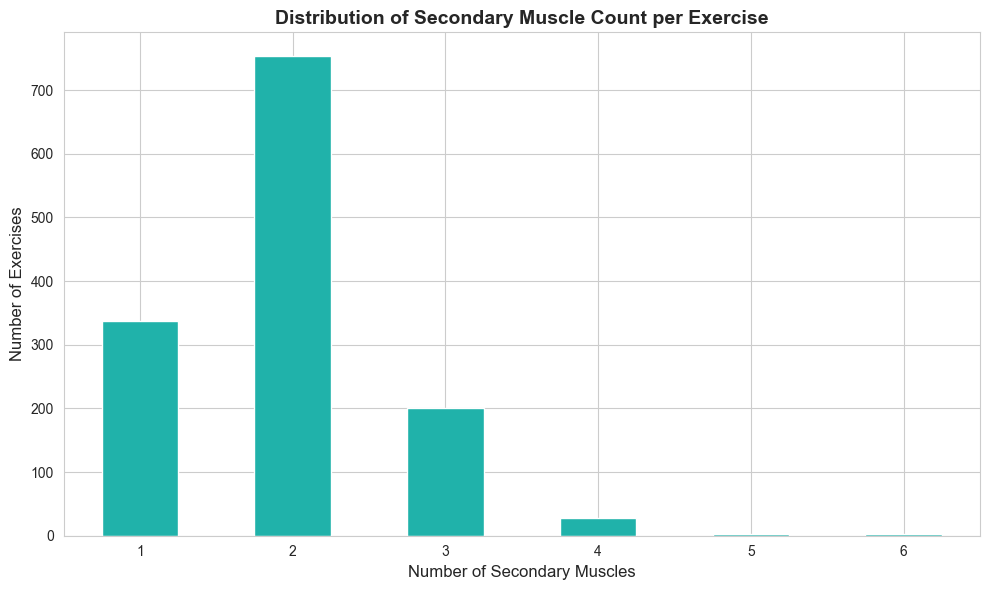

In [31]:
# Analyze secondary muscle coverage
df['secondary_muscle_count'] = df['secondaryMuscles'].apply(
    lambda x: len(parse_secondary_muscles(x)) if pd.notna(x) else 0
)

print("Secondary Muscle Analysis:")
print("=" * 80)
print(f"Exercises with no secondary muscles: {(df['secondary_muscle_count'] == 0).sum()}")
print(f"Exercises with 1 secondary muscle: {(df['secondary_muscle_count'] == 1).sum()}")
print(f"Exercises with 2 secondary muscles: {(df['secondary_muscle_count'] == 2).sum()}")
print(f"Exercises with 3+ secondary muscles: {(df['secondary_muscle_count'] >= 3).sum()}")
print(f"\nAverage secondary muscles per exercise: {df['secondary_muscle_count'].mean():.2f}")
print(f"Max secondary muscles in a single exercise: {df['secondary_muscle_count'].max()}")

# Visualization
plt.figure(figsize=(10, 6))
df['secondary_muscle_count'].value_counts().sort_index().plot(kind='bar', color='lightseagreen')
plt.title('Distribution of Secondary Muscle Count per Exercise', fontsize=14, fontweight='bold')
plt.xlabel('Number of Secondary Muscles', fontsize=12)
plt.ylabel('Number of Exercises', fontsize=12)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 11. Summary Statistics

In [32]:
print("=" * 80)
print("SUMMARY STATISTICS")
print("=" * 80)

print(f"\n📊 Dataset Overview:")
print(f"   Total Exercises: {len(df)}")
print(f"   Unique Body Parts: {df['bodyPart'].nunique()}")
print(f"   Unique Primary Target Muscles: {df['target'].nunique()}")
print(f"   Unique Muscle Groups (Primary + Secondary): {len(muscle_df)}")
print(f"   Unique Equipment Types: {df['equipment'].nunique()}")
print(f"   Unique Difficulty Levels: {df['difficulty'].nunique()}")

print(f"\n🎯 Top 5 Primary Target Muscles:")
for i, (muscle, count) in enumerate(primary_target_counts.head(5).items(), 1):
    print(f"   {i}. {muscle}: {count} exercises")

print(f"\n💪 Top 5 Muscle Groups (Including Secondary):")
for i, (idx, row) in enumerate(muscle_df.head(5).iterrows(), 1):
    print(f"   {i}. {row['Muscle Group']}: {int(row['Exercise Count'])} exercises")

print(f"\n📈 Most Common Body Part: {bodypart_counts.index[0]} ({bodypart_counts.iloc[0]} exercises)")
print(f"📈 Most Common Equipment: {equipment_counts.index[0]} ({equipment_counts.iloc[0]} exercises)")
print(f"📈 Most Common Difficulty: {difficulty_counts.index[0]} ({difficulty_counts.iloc[0]} exercises)")

SUMMARY STATISTICS

📊 Dataset Overview:
   Total Exercises: 1324
   Unique Body Parts: 10
   Unique Primary Target Muscles: 19
   Unique Muscle Groups (Primary + Secondary): 50
   Unique Equipment Types: 34
   Unique Difficulty Levels: 3

🎯 Top 5 Primary Target Muscles:
   1. abs: 169 exercises
   2. pectorals: 158 exercises
   3. biceps: 151 exercises
   4. glutes: 144 exercises
   5. delts: 143 exercises

💪 Top 5 Muscle Groups (Including Secondary):
   1. triceps: 409 exercises
   2. shoulders: 400 exercises
   3. biceps: 345 exercises
   4. hamstrings: 317 exercises
   5. forearms: 314 exercises

📈 Most Common Body Part: upper arms (292 exercises)
📈 Most Common Equipment: body weight (324 exercises)
📈 Most Common Difficulty: intermediate (589 exercises)
